# E-L: sensitivity to working number of signals

100 paired linear-model trials; true L*=4 and changes at 0.20, 0.50, 0.80. Working $\hat{L}=1,\ldots,6$; fixed-$\hat{L}$ unpenalized WERM least squares, no CV or truth passed to estimator. Because this is exact fixed-L, count=L-1 and L=1 is always empty. Conditional Hausdorff omits empty fits; unconditional loss explicitly charges empty and count mismatch. From the saved 100 paired trials, the mean/median conditional Hausdorff errors are $L=2$: $0.310/0.304$, $L=3$: $0.234/0.236$, $L=4$: $0.049/0.038$, $L=5$: $0.060/0.053$, and $L=6$: $0.125/0.128$ (undefined for empty $L=1$ fits). Thus both the Mean conditional Hausdorff and the median conditional Hausdorff are minimized at $L=4$. The saved artifact retains conditional population-risk calculations only at matched L=4, not a finite-sample or misspecification guarantee. Set WERM_SMOKE=1 to run two paired trials before full execution.

### Paper-ready experiment description

Across 100 paired Monte Carlo trials (base seed 20260916), we generated $n=500$ observations with $p=100$ covariates, $x_i\sim N(0,I_p/n)$ and $y_i=x_i^\top\beta_{s(i)}+\varepsilon_i$, where $\varepsilon_i\sim N(0,0.5^2)$. The true $L^*=4$ regimes change at fractional locations $(0.20,0.50,0.80)$; the initial coefficient vector is $N(0,(n/p)I_p)$ and independent successive jumps are $N(0,1.5^2(n/p)I_p)$. On the same data in each trial, we fit fixed-$L$ unpenalized least-squares WERM for $L\in\{1,2,3,4,5,6\}$ with minimum change-point gap $\Delta_n=1$, half-squared-error loss, and the package's analytic signal weights $\pi_i^{(\ell)}=\binom{L-1}{\ell}(i/n)^\ell(1-i/n)^{L-1-\ell}$ ($i=1,\ldots,n$; $\ell=0,\ldots,L-1$). Each fit selects exactly $L-1$ changes without cross-validation; we record selected count, empty-fit rate, conditional Hausdorff error divided by $n$, unconditional location-and-count loss, and runtime. Conditional population-risk calculations are retained only for the correctly specified $L=4$ fit.


In [1]:

import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
from pathlib import Path
from time import perf_counter
import pickle
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from scipy.special import comb
from WERM.estimators import weighted_erm
from WERM.gof import chgpt_gof_dp

plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    "font.family": "serif", "font.size": 13, "axes.labelsize": 16,
    "axes.titlesize": 17, "legend.fontsize": 12,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
SMOKE_MODE = os.environ.get("WERM_SMOKE") == "1"
N_TRIALS = 2 if SMOKE_MODE else 100
N_JOBS = 2 if SMOKE_MODE else 36
SEED = 20260916
P = 100
N = 500
NOISE_SD = 0.5
M = lambda prediction, truth: 0.5 * (np.asarray(prediction) - np.asarray(truth)) ** 2

def make_paired_data(trial, true_cp):
    """Identical X, y and signals across methods within trial."""
    rng = np.random.default_rng(np.random.SeedSequence([SEED, trial]))
    delta = N / P
    beta = np.empty((P, len(true_cp) + 1))
    beta[:, 0] = rng.normal(size=P) * np.sqrt(delta)
    for segment in range(1, beta.shape[1]):
        beta[:, segment] = beta[:, segment - 1] + 1.5 * np.sqrt(delta) * rng.normal(size=P)
    X = rng.normal(size=(N, P)) / np.sqrt(N)
    signal = np.searchsorted(true_cp, np.arange(N), side="right")
    y = np.einsum("ij,ij->i", X, beta[:, signal].T) + rng.normal(0, NOISE_SD, N)
    return X, y, beta, signal

def error_metrics(cp, truth):
    """Normalized symmetric nearest-neighbor loss, defined even at the empty set.

    U(A,B) = 0.5*[mean_a min_b |a-b|/n + mean_b min_a |a-b|/n]
             + 0.25*||A|-|B||/max(1,|A|,|B|).
    Missing-direction distance is 1. Hausdorff is reported only for nonempty B.
    """
    a, b = np.asarray(truth, int), np.asarray(cp, int)
    if b.size:
        pair = np.abs(a[:, None] - b[None, :]) / N
        directed_a = float(pair.min(axis=1).mean())
        directed_b = float(pair.min(axis=0).mean())
        haus = float(max(pair.min(axis=1).max(), pair.min(axis=0).max()))
    else:
        directed_a = directed_b = 1.0
        haus = np.nan
    count_penalty = 0.25 * abs(len(a) - len(b)) / max(1, len(a), len(b))
    return dict(count=len(b), empty=(len(b) == 0),
                conditional_haus=haus,
                exact_count_haus=haus if len(a) == len(b) else np.nan,
                unconditional_loss=0.5 * (directed_a + directed_b) + count_penalty)

def conditional_coefficient_mse(X, beta, true_signal, phi):
    """Exact E_noise[mean((B_hat-B_true)^2) | X,B_true] for this weighted LS fit.

    B_hat_l = A_l y, A_l=(X'W_l X)^(-1) X'W_l. Thus the conditional
    expectation is squared bias plus noise_sd^2 * ||A_l||_F^2. This is an
    exact finite-sample coefficient prediction, not a CP-risk theorem.
    """
    from scipy.linalg import cho_factor, cho_solve
    mu = np.einsum("ij,ij->i", X, beta[:, true_signal].T)
    total = 0.0
    for l, weight in enumerate(phi):
        w = weight / weight.sum()
        gram = X.T @ (w[:, None] * X)
        right = X.T * w
        try:
            A = cho_solve(cho_factor(gram, lower=True, check_finite=False),
                          right, check_finite=False)
        except np.linalg.LinAlgError:
            A = np.linalg.pinv(gram) @ right
        bias = A @ mu - beta[:, l]
        total += float(bias @ bias + NOISE_SD**2 * np.sum(A*A))
    return total / beta.shape[0] / beta.shape[1]

def population_prediction(beta, true_signal, phi, delta_n):
    """Conditional population-risk comparator for the *same* weighted fixed-L ERM.

    With X_i~N(0,I/n), E[w_i (y_i-X_i b)^2] is minimized at
    b_l = sum_i phi[l,i] beta_{s(i)} / sum_i phi[l,i].
    The expected per-time GOF is 0.5*(noise_sd^2+||beta_s-b_l||^2/n).
    This is a population prediction, NOT a finite-sample theorem or fixed-point
    prediction. It uses the identical phi, L, loss, and partition search.
    """
    L = phi.shape[0]
    row_mass = phi.sum(axis=1)
    mixture = np.column_stack([
        np.bincount(true_signal, weights=phi[l], minlength=beta.shape[1]) / row_mass[l]
        for l in range(L)
    ])
    beta_pop = beta @ mixture
    risk = np.empty((N, L))
    for l in range(L):
        squared = np.sum((beta[:, true_signal].T - beta_pop[:, l])**2, axis=1) / N
        risk[:, l] = 0.5 * (NOISE_SD**2 + squared)
    result = chgpt_gof_dp(lambda column, unused: column, risk, np.zeros(N),
                          N, L, delta_n, L_is_upper_bound=False)
    return result["changepoints"], beta_pop


# E-L: fixed-L least-squares WERM, including severe under/over-specification.
TRUE_CP = np.rint(N * np.array([0.20, 0.50, 0.80])).astype(int)
TRUE_L = len(TRUE_CP) + 1
WORKING_L = np.arange(1, 7)
DELTA_N = 1  # The package's exact-L default analytic marginal branch.
ARTIFACT = RESULTS_DIR / ("E_L_fixedL_L1to6_100paired_seed20260916_smoke.pkl" if SMOKE_MODE
                          else "E_L_fixedL_L1to6_100paired_seed20260916.pkl")

def analytic_fixed_l_marginals(L):
    # Exactly the Delta_n=1 formula used inside weighted_erm (i=1,...,n).
    x = np.arange(1, N + 1) / N
    phi = np.array([comb(L-1, l) * x**l * (1-x)**(L-1-l)
                    for l in range(L)], dtype=float)
    assert np.allclose(phi.sum(axis=0), 1)
    return phi

def run_trial(trial):
    X, y, beta, signal = make_paired_data(trial, TRUE_CP)
    output = {}
    for L in WORKING_L:
        tic = perf_counter()
        cp, beta_hat = weighted_erm(
            X, y, M, L=int(L), Delta_n=DELTA_N, gamma=0.0,
            L_is_upper_bound=False, return_B_hat=True,
            coefficient_loss="least_squares", coefficient_penalty="none")
        elapsed = perf_counter() - tic
        assert len(cp) == L - 1  # exact fixed-L, not model-selection CV
        output[int(L)] = dict(cp=np.asarray(cp), runtime=elapsed,
                              **error_metrics(cp, TRUE_CP))
        if L == TRUE_L:
            phi = analytic_fixed_l_marginals(int(L))
            theory_cp, beta_pop = population_prediction(beta, signal, phi, DELTA_N)
            output[int(L)]["population_cp"] = theory_cp
            output[int(L)]["population_loss"] = error_metrics(theory_cp, TRUE_CP)["unconditional_loss"]
            output[int(L)]["coefficient_mse"] = float(np.mean((beta_hat-beta)**2))
            output[int(L)]["conditional_expected_coefficient_mse"] = (
                conditional_coefficient_mse(X, beta, signal, phi))
            output[int(L)]["population_coefficient_bias"] = float(np.mean((beta_pop-beta)**2))
    return output

with parallel_config(backend="loky", inner_max_num_threads=1):
    trials = Parallel(n_jobs=N_JOBS, verbose=10)(delayed(run_trial)(t) for t in range(N_TRIALS))
assert len(trials) == N_TRIALS
assert all(set(row) == set(WORKING_L) for row in trials)
with ARTIFACT.open("wb") as handle:
    pickle.dump(dict(trials=trials, params=dict(N=N, P=P, true_cp=TRUE_CP,
        working_L=WORKING_L, delta_n=DELTA_N, n_trials=N_TRIALS,
        n_jobs=N_JOBS, seed=SEED, theory_kind="conditional population risk; matched L=4 only")), handle)
print(f"Saved {N_TRIALS} paired trials to {ARTIFACT}")


Saved 100 paired trials to results/E_L_fixedL_L1to6_100paired_seed20260916.pkl


## Load and plot with tighter layout

This cell loads the unique saved artifact; re-running plots does not rerun trials.

E-L: 100 paired trials, n=500, p=100; artifact: results/E_L_fixedL_L1to6_100paired_seed20260916.pkl
L | count | empty rate | mean / median conditional Hausdorff | exact-count Hausdorff | unconditional loss | runtime s
1 | 0.00 | 100.00% | nan / nan | nan | 1.250 | 0.003
2 | 1.00 | 0.00% | 0.310 / 0.304 | nan | 0.273 | 0.005
3 | 2.00 | 0.00% | 0.234 / 0.236 | nan | 0.196 | 0.055
4 | 3.00 | 0.00% | 0.049 / 0.038 | 0.049 | 0.023 | 0.106
5 | 4.00 | 0.00% | 0.060 / 0.053 | nan | 0.081 | 0.153
6 | 5.00 | 0.00% | 0.125 / 0.128 | nan | 0.126 | 0.192
Conditional localization by working L-hat (mean ± SE, then trial distributions).


/tmp/ipykernel_4003179/1551600467.py:78: RuntimeWarning: Mean of empty slice
  f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f} | "
/tmp/ipykernel_4003179/1551600467.py:78: RuntimeWarning: All-NaN slice encountered
  f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f} | "


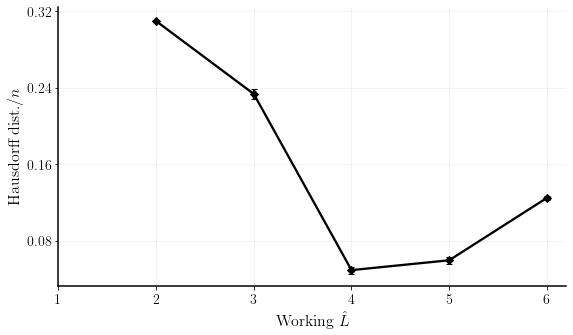

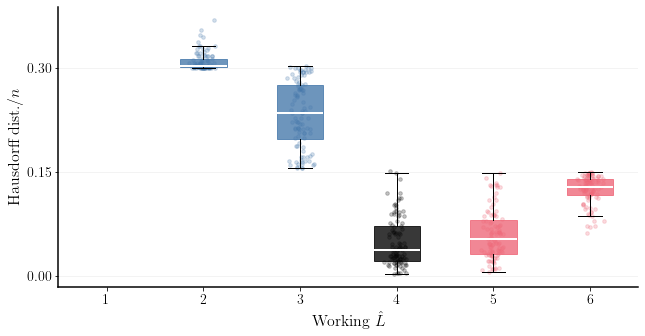

Estimated change-point locations; panels left-to-right: working L-hat = 1, 2, 3, 4, 5, 6. Dashed lines mark truth.


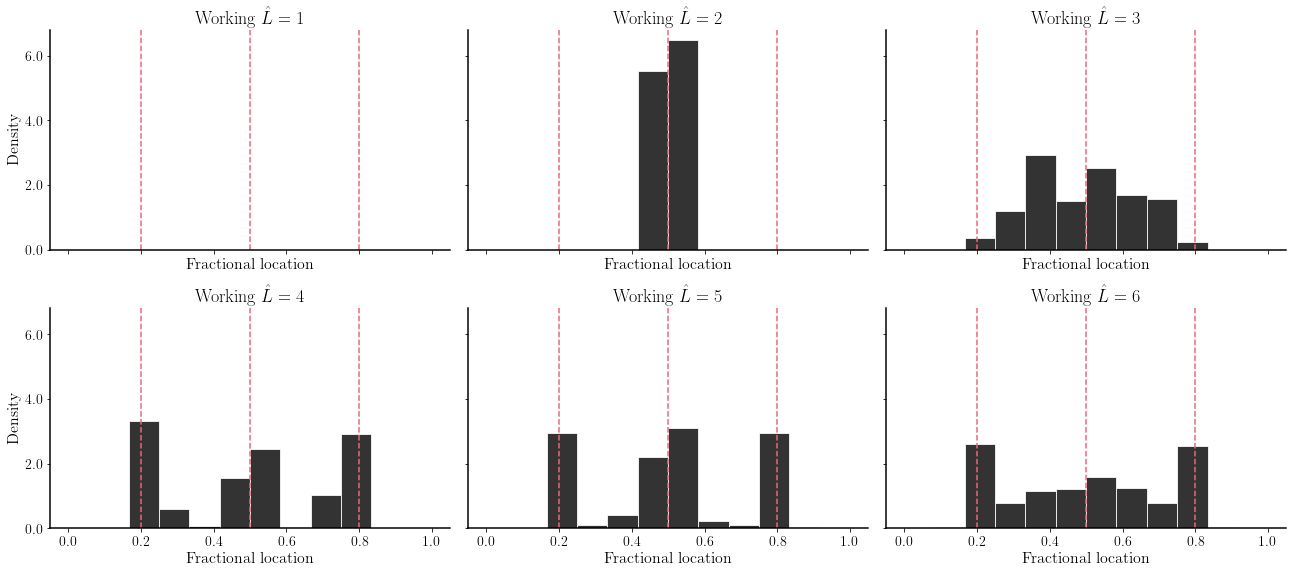

In [2]:

import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    "font.family": "serif", "font.size": 14, "axes.labelsize": 16,
    "axes.linewidth": 1.5, "axes.titlesize": 18, "legend.fontsize": 14,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "font.serif": ["Computer Modern Roman", "Times New Roman", "DejaVu Serif"],
    "text.usetex": True,
    "lines.linewidth": 3.0, "lines.markersize": 8,
    "figure.dpi": 72, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
})
SMOKE_MODE = __import__("os").environ.get("WERM_SMOKE") == "1"

def series(trials, key, metric):
    return np.array([row[key][metric] for row in trials], dtype=float)

def mean_se(values):
    finite = np.isfinite(values)
    count = finite.sum(axis=0)
    mean = np.divide(np.nansum(values, axis=0), count,
                     out=np.full(values.shape[1], np.nan), where=count > 0)
    centered = np.where(finite, values - mean, 0)
    sd = np.sqrt(np.divide((centered**2).sum(axis=0), np.maximum(count-1, 1)))
    se = np.divide(sd, np.sqrt(count), out=np.zeros_like(sd), where=count > 0)
    return mean, se

def line_panel(ax, x, values, ylabel, color="black", theory=None):
    mean, se = mean_se(values)
    ax.errorbar(x, mean, yerr=se, color=color, marker="D", linestyle="-",
                linewidth=2.3, markersize=5, capsize=3, label="WERM")
    if theory is not None:
        ax.plot(x, theory, marker="o", linestyle="--", color="#AA3377",
                linewidth=1.7, markersize=4, label="Population")
        ax.legend(frameon=False)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.18)

def jitter_boxes(ax, grouped, labels, ylabel, colors):
    rng = np.random.default_rng(2901)
    positions = np.arange(1, len(grouped)+1)
    clean = [np.asarray(g)[np.isfinite(g)] for g in grouped]
    for k, values in enumerate(clean):
        if len(values):
            ax.scatter(rng.normal(positions[k], .055, len(values)), values,
                       s=13, alpha=.23, color=colors[k], zorder=2)
    bp = ax.boxplot([g if len(g) else [np.nan] for g in clean],
                    positions=positions, widths=.48, patch_artist=True,
                    showfliers=False, medianprops=dict(color="white", linewidth=2))
    for patch, color in zip(bp["boxes"], colors):
        patch.set(facecolor=color, edgecolor=color, alpha=.78)
    ax.set_xticks(positions, labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=.18)


from matplotlib.ticker import MaxNLocator, FormatStrFormatter
ARTIFACT = Path("results") / ("E_L_fixedL_L1to6_100paired_seed20260916_smoke.pkl" if SMOKE_MODE
                              else "E_L_fixedL_L1to6_100paired_seed20260916.pkl")
with ARTIFACT.open("rb") as handle:
    payload = pickle.load(handle)
trials, params = payload["trials"], payload["params"]
L_values = np.asarray(params["working_L"])
true_cp, n = np.asarray(params["true_cp"]), params["N"]
metrics = ["conditional_haus", "empty", "count", "runtime", "unconditional_loss"]
arrays = {m: np.column_stack([series(trials, int(L), m) for L in L_values]) for m in metrics}
print(f"E-L: {len(trials)} paired trials, n={n}, p={params['P']}; artifact: {ARTIFACT}")
print("L | count | empty rate | mean / median conditional Hausdorff | exact-count Hausdorff | unconditional loss | runtime s")
for L in L_values:
    rows = [row[int(L)] for row in trials]
    avg = lambda key: np.nanmean([r[key] for r in rows])
    conditional = np.asarray([r["conditional_haus"] for r in rows], dtype=float)
    exact = np.array([r["exact_count_haus"] for r in rows])
    print(f"{L} | {avg('count'):.2f} | {avg('empty'):.2%} | "
          f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f} | "
          f"{np.nanmean(exact) if np.isfinite(exact).any() else np.nan:.3f} | "
          f"{avg('unconditional_loss'):.3f} | {avg('runtime'):.3f}")

plt.rcParams.update({"font.size": 14, "xtick.labelsize": 14,
                     "ytick.labelsize": 14, "legend.fontsize": 14})
print("Conditional localization by working L-hat (mean ± SE, then trial distributions).")
fig, ax = plt.subplots(figsize=(8, 4.7))
line_panel(ax, L_values, arrays["conditional_haus"], r"Hausdorff dist./$n$")
ax.set_xlabel(r"Working $\hat{L}$"); ax.set_xticks(L_values)
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
fig.tight_layout(pad=.6)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.7))
labels = [str(v) for v in L_values]
colors = ["#4477AA" if v < 4 else "black" if v == 4 else "#EE6677" for v in L_values]
jitter_boxes(ax, [arrays["conditional_haus"][:, j] for j in range(len(L_values))],
             labels, r"Hausdorff dist./$n$", colors)
ax.set_xlabel(r"Working $\hat{L}$")
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
fig.tight_layout(pad=.6)
plt.show()

print("Estimated change-point locations; panels left-to-right: working L-hat = 1, 2, 3, 4, 5, 6. Dashed lines mark truth.")
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True, sharey=True)
for ax, L in zip(axes.flat, L_values):
    cps = np.concatenate([row[int(L)]["cp"] / n for row in trials])
    if len(cps):
        ax.hist(cps, bins=12, range=(0, 1), density=True,
                color="black", edgecolor="white", alpha=.8)
    for cp in true_cp / n: ax.axvline(cp, color="#EE6677", linestyle="--", linewidth=1.5)
    ax.set_title(rf"Working $\hat{{L}}={L}$")
    ax.set_xlabel("Fractional location")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
axes[0, 0].set_ylabel("Density")
axes[1, 0].set_ylabel("Density")
fig.tight_layout(pad=.6, w_pad=1.0, h_pad=1.0)
plt.show()


## Upper-bound $L$ experiment moved

The extra upper-bound experiment is now in [E_L_upper_bound.ipynb](E_L_upper_bound.ipynb), with plots exclusively for $n=1000$, $p=100$ and the gold-standard final-notebook style.

The original four fixed-working-count cells above are preserved. The previous upper-bound study, both original review comments, its diagnostics, and all outputs are preserved in the [archived notebook](results/notebook_archive/20261019_extra_experiments/E_L_misspecified_L.ipynb). The exact search-penalty experiments are in [E_search_penalty.ipynb](E_search_penalty.ipynb).


## Updated consistent plots

Plotting reference: **Canonical M1 tighter-layout plots (alpha = 0.3)** in `M1_upsample_final.ipynb`. Error-bar plots use its 5 by 4 inch canvas, 18 pt axis labels and 14 pt ticks; among Hausdorff, count and runtime comparisons, only Runtime displays a legend. These cells load saved results only; the original experiment and plotting cells above are unchanged. Run the setup below, then the desired plotting cell. PDFs and PNGs are saved under `results/consistent_plots_20261102/E_L_fixed/`.

Line summaries retain their original statistic (quartile-distance bars, or mean ± SE where stated); boxplots use 1.5-IQR whiskers and faint deterministic trial jitter. Histograms follow canonical M1: 12 data-range bins, five-fold bandwidth-selected Gaussian KDE, grey overlay, truth-position ticks, and density range 0–18. These histogram display choices can differ from the older plots; the samples do not change. Empty estimates are omitted from conditional localization and pooled location densities, not assigned zero error. Histograms retain every selected setting and method in one grid, with no three-row or three-column cap: 2.5 inches per column and 2.2 inches per row, matching the reference. Other diagnostic plots retain their compact presentation.

In [1]:
"""Approved publication style; also embedded verbatim in final notebook cells.

Only plotting helpers live here. All data choices and plot calls are visible in
the notebook cells. No fitting, simulation, CV for estimators, or job submission.
Histogram KDE bandwidth CV is the canonical M1 visualization procedure.
"""
from pathlib import Path
import hashlib
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from IPython.display import display, Image

PAPER_WIDTH = 427.64493 / 72.27
PANEL_WIDTH = .49 * PAPER_WIDTH
SCALE = 10.5 / 18
PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

# Reference: M1_upsample_final, "Canonical M1 tighter-layout plots (alpha=0.3)".
# Keep this separate from the compact style used for unrelated diagnostic plots.
CANONICAL_STYLE = {
    **PAPER_STYLE,
    'font.size': 14, 'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'legend.frameon': True, 'legend.fancybox': True,
    'legend.edgecolor': 'black', 'legend.framealpha': .95,
    'lines.linewidth': 4, 'lines.markersize': 8,
    'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.pad_inches': .1,
}

METHODS = {
    'McScan': ('McScan', '#AA3377', 'o', '--'),
    'MOSEG': ('MOSEG', '#228833', 's', '-.'),
    'DCDP': ('DCDP', '#EE6677', 'X', '--'),
    'DPDU': ('DPDU', '#4477AA', 'P', ':'),
    'charcoal': ('charcoal', '#336677', 'v', '-.'),
    'GLMBSA-CV': ('GLMBSA', '#E69F00', 'p', ':'),
    'WERM-unp': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-unp-10fold': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-L1-jointCV': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
    'WERM-L1-fullCV-2fold': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
}
SOURCE_HASHES, FIGURE_AUDIT = {}, []
KDE_CACHE = {}

def load_saved(filename):
    path = Path(filename)
    raw = path.read_bytes()  # fail explicitly if a result is missing; no dummy data
    SOURCE_HASHES[str(path)] = hashlib.sha256(raw).hexdigest()
    return pickle.loads(raw)

def clean(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def paper_panel(full=False, height=2.05):
    fig, ax = plt.subplots(figsize=(PAPER_WIDTH if full else PANEL_WIDTH, height))
    fig.subplots_adjust(left=.11 if full else .19, right=.98, bottom=.23, top=.97)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    return fig, ax

def export_plot(fig, name, description=''):
    """Export PDF + embedded PNG, retaining canonical geometry and input hashes."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    canonical = getattr(fig, '_canonical_m1', False)
    bounds = fig.get_tightbbox(renderer).padded(.1) if canonical else fig.bbox_inches
    pixels = bounds.transformed(fig.dpi_scale_trans)
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer)
        if bbox is not None:
            assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2, (name, 'left/bottom clipping', bbox)
            assert bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'right/top clipping', bbox)
    for text in fig.texts:
        bbox = text.get_window_extent(renderer)
        assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2 and bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'figure text clipping')
    fig.savefig(OUTPUT_DIR / f'{name}.pdf', bbox_inches=bounds)
    fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches=bounds)
    FIGURE_AUDIT.append(dict(name=name, description=description,
        size_inches=[bounds.width, bounds.height],
        canvas_inches=fig.get_size_inches().tolist(),
        canonical_m1=canonical,
        legends=sum(a.get_legend() is not None for a in fig.axes)+len(fig.legends),
        axes=[dict(bounds=list(a.get_position().bounds), xlabel=a.get_xlabel(),
                   ylabel=a.get_ylabel(), title=a.get_title(), ylim=list(a.get_ylim())) for a in fig.axes]))
    print(description or name)
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
    plt.close(fig)
    (OUTPUT_DIR/'manifest.json').write_text(json.dumps(dict(
        style=PAPER_STYLE, sources=SOURCE_HASHES, figures=FIGURE_AUDIT), indent=2))

def verify_sources():
    for path, digest in SOURCE_HASHES.items():
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
    print(f'Exported {len(FIGURE_AUDIT)} figures to {OUTPUT_DIR}; saved inputs unchanged.')

def error_series(ax, x, groups, label, color='black', marker='D', ls='-', error='quartile', scale=SCALE):
    xplot, means, low, high = [], [], [], []
    for xx, group in zip(x, groups):
        v = clean(group)
        if not len(v):
            continue
        mean = v.mean()
        if error == 'se':
            lo = hi = v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else 0
        else:
            q25, q75 = np.percentile(v, [25,75])
            lo, hi = abs(mean-q25), abs(q75-mean)
        xplot.append(xx); means.append(mean); low.append(lo); high.append(hi)
    ax.errorbar(xplot,means,yerr=[low,high],label=label,color=color,marker=marker,ls=ls,
        linewidth=3.5*scale,markersize=8*scale,capsize=4*scale,capthick=2*scale,
        markeredgewidth=2*scale,markeredgecolor='white',alpha=.8)

def box_group(ax, values, position, color, rng, width=.65, jitter=.19):
    v=clean(values)
    if not len(v):
        return
    bp=ax.boxplot([v],positions=[position],widths=width,patch_artist=True,
        showfliers=False,whis=1.5,autorange=True,manage_ticks=False,
        medianprops=dict(color='black',linewidth=2.3*SCALE,zorder=6),
        boxprops=dict(color='black',linewidth=1.35*SCALE),
        whiskerprops=dict(color='black',linewidth=1.25*SCALE),
        capprops=dict(color='black',linewidth=1.25*SCALE))
    bp['boxes'][0].set(facecolor=color,alpha=.28)
    ax.scatter(position+rng.uniform(-jitter,jitter,len(v)),v,s=3,alpha=.12,
               color=color,linewidths=0,zorder=4)
    q25,med,q75=np.percentile(v,[25,50,75])
    if np.isclose(q25,q75,rtol=1e-10,atol=1e-12*max(1.,np.max(np.abs(v)))):
        ax.plot([position-.43*width,position+.43*width],[med,med],
                color='black',lw=3.4*SCALE,zorder=7)

def histogram_grid(groups, titles, colors, truth, name, row_labels=None,
                   panel_titles=None, density_limit=18):
    """Canonical M1 histogram grid with every selected row and method column.

    groups[row][column] contains pooled fractional change-point estimates.
    Uses the exact M1 12-bin/data-range and five-fold Gaussian-KDE setup.
    The fixed canonical density range is retained; clipped peaks are reported.
    """
    with plt.rc_context(CANONICAL_STYLE):
        rows, cols=len(groups),len(titles)
        assert rows>=1 and cols>=1 and all(len(g)==cols for g in groups)
        fig, axes=plt.subplots(rows,cols,figsize=(2.5*cols,2.2*rows),
            sharex=True,sharey=True,squeeze=False,
            gridspec_kw=dict(wspace=.05,hspace=.55 if panel_titles and rows>1 else .08))
        fig._canonical_m1 = True
        peak=0.
        for row in range(rows):
            for col in range(cols):
                ax=axes[row,col]; values=clean(groups[row][col])
                assert np.all((values>=0)&(values<=1)), 'Histogram expects fractional locations'
                if len(values):
                    hist, edges, _=ax.hist(values,bins=12,alpha=.8,color=colors[col],
                        density=True,edgecolor='white',linewidth=1.0)
                    assert np.isclose(np.sum(hist*np.diff(edges)),1)
                    peak=max(peak,float(hist.max()))
                    if len(values)>6:
                        key=hashlib.sha256(values.tobytes()).hexdigest()
                        if key not in KDE_CACHE:
                            cv=GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth':np.logspace(-2,0,50)},cv=5,n_jobs=1)
                            cv.fit(values.reshape(-1,1))
                            x=np.linspace(0,1,200)
                            KDE_CACHE[key]=(x,np.exp(cv.best_estimator_.score_samples(x.reshape(-1,1))))
                        x,y=KDE_CACHE[key]
                        ax.plot(x,y,color='#555555',lw=1.0,ls='-',alpha=.8,zorder=2)
                        ax.fill_between(x,y,color='#999999',alpha=.2,zorder=1)
                        peak=max(peak,float(y.max()))
                else:
                    ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,
                        ha='center',va='center',fontsize=12,alpha=.7)
                for cp in truth:
                    ax.axvline(cp,color='black',ls='--',lw=2,alpha=.9,zorder=10)
                ax.set(xlim=(0,1),ylim=(0,density_limit))
                ax.set_xticks(truth,[f'${cp:.2f}$' for cp in truth])
                ax.set_yticks([0,8,16] if density_limit==18 else [0,density_limit/2,density_limit])
                ax.tick_params(width=1,length=4,labelsize=14)
                for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1)
                if row==0 or panel_titles:
                    ax.set_title(panel_titles[row][col] if panel_titles else titles[col],
                                 fontsize=18,pad=10)
                if col==cols-1 and row_labels:
                    ax.text(1.05,.5,row_labels[row],transform=ax.transAxes,rotation=90,
                        va='center',ha='left',fontsize=18)
        fig.text(.5,.01,'Fractional location',ha='center',va='bottom',fontsize=18)
        fig.text(.07,.5,'Density',va='center',rotation='vertical',fontsize=18)
        fig.tight_layout(rect=[.03,.05,.96,.96])
        # Keep the shared x label clear of tick labels in shorter grids.
        if rows==1:fig.subplots_adjust(bottom=.28,top=.78)
        elif rows==2:fig.subplots_adjust(bottom=.16)
        if peak>density_limit:
            print(f'{name}: maximum density {peak:.2f}; canonical display limit {density_limit} (peaks above this are clipped).')
        export_plot(fig,name,'Change-point location histograms: canonical M1 bins, KDE, ticks and layout.')

def comparison_plots(filename, prefix, methods, min_x=None, m3=False,
                     histogram_stride=3, metrics=('haus','size','runtime'), histograms=True):
    payload=load_saved(filename); results,params=payload['results'],payload['params']
    raw_x=np.asarray(params['kappa_list'] if m3 else params['delta_list'])
    keep=np.flatnonzero(raw_x>=min_x) if min_x is not None else np.arange(len(raw_x))
    x=raw_x[keep]**2 if m3 else raw_x[keep]
    xlabel=r'$\kappa^2$' if m3 else r'$\delta=n/p$'
    truth=np.asarray(params['fractional_chgpt_locations'])
    values={}
    for method in methods:
        sizes=np.asarray(results['size_'+method],float)[keep]
        assert sizes.shape[1]==params['num_trials']
        for metric in metrics:
            v=(np.abs(sizes-len(truth)) if metric=='size_error' else
               np.asarray(results[metric+'_'+method],float)[keep].copy())
            if metric=='haus':v=np.where(sizes>0,v,np.nan)
            if metric=='size_error':v=np.abs(sizes-len(truth))
            values[metric,method]=v
    for metric in metrics:
        ylabel={'haus':r'Hausdorff dist. / $n$','size':'No. change points',
                'runtime':'Runtime (s)','size_error':'Set size error'}[metric]
        for kind in ('line','box'):
            with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5.,4.))
                    fig._canonical_m1 = True
                else:
                    fig,ax=paper_panel()
                rng=np.random.default_rng(42)
                handles=[]
                for j,method in enumerate(methods):
                    label,color,marker,ls=METHODS[method];v=values[metric,method]
                    if kind=='line':
                        error_series(ax,x,v,label,color,marker,ls,scale=1)
                    else:
                        for k,g in enumerate(v):box_group(ax,g,k*(len(methods)+1)+j,color,rng)
                        handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
                if kind=='line':
                    if m3:
                        # Preserve the canonical M3 logarithmic kappa-squared axis.
                        ax.set_xscale('log')
                        ax.set_xticks([10,100,1000],['10','100','1000'])
                        ax.xaxis.set_minor_formatter(NullFormatter())
                    else:
                        ax.set_xticks(x[::2],[f'{xx:g}' for xx in x[::2]])
                else:
                    ax.set_xticks(np.arange(len(x))[::2]*(len(methods)+1)+(len(methods)-1)/2,
                                  [f'{xx:.0f}' if m3 else f'{xx:g}' for xx in x[::2]])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='size':
                    ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(bottom=-.15)
                    if m3:
                        ax.set_ylim(0,params['L']);ax.set_yticks(np.arange(params['L']+1))
                elif metric=='size_error':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
                elif metric=='runtime':ax.set_ylim(bottom=0)
                if metric=='runtime':
                    ax.legend(handles=handles if kind=='box' else None,loc='best',
                              prop={'size':14 if kind=='line' else 8},
                              fancybox=True,framealpha=.4)
                if kind=='line':
                    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
                    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
                    for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1.5)
                    fig.tight_layout()
                export_plot(fig,f'{prefix}_{metric}_{kind}',
                    f'{prefix}: {ylabel}; '+('mean and absolute distances to quartiles' if kind=='line' else 'boxplots with faint trial jitter'))
    if not histograms:return
    # Preserve all selected settings and methods in one canonical grid.
    row_idx=keep[::histogram_stride]
    keys=list(reversed(methods));groups=[]
    for index in row_idx:
        n=int(params['p']*(params['fixed_delta'] if m3 else raw_x[index]))
        group=[]
        for key in keys:
            parts=[np.asarray(cps).ravel() for i,cps in results['chgpts_'+key] if i==index]
            cp=np.concatenate(parts) if parts else np.array([])
            group.append(cp[cp!=-1]/n)
        groups.append(group)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        f'{prefix}_hist',
        [rf'$\kappa^2={raw_x[i]**2:.0f}$' if m3 else rf'$\delta={raw_x[i]:g}$' for i in row_idx])


def simple_summary(groups, x, xlabel, ylabel, name, colors=None, error='quartile',
                   kind='box', labels=None, truth=None, title=None):
    with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
        canonical = kind=='line'
        fig,ax=plt.subplots(figsize=(5.,4.)) if canonical else paper_panel()
        fig._canonical_m1 = canonical
        colors=colors or ['black']*len(x)
        if kind=='line':error_series(ax,x,groups,'',error=error,scale=1)
        else:
            rng=np.random.default_rng(42)
            for xx,g,color in zip(x,groups,colors):box_group(ax,g,xx,color,rng,width=.55,jitter=.16)
        ax.set_xticks(x,labels or [str(xx) for xx in x])
        ax.set(xlabel=xlabel,ylabel=ylabel)
        if truth is not None:ax.axhline(truth,color='gray',lw=2.5*(1 if canonical else SCALE),alpha=.8,zorder=0)
        if title:
            fig.subplots_adjust(top=.86)
            ax.set_title(title,pad=4)
        if ylabel=='No. change points':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
        if canonical:
            ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
            fig.tight_layout()
        export_plot(fig,name)

OUTPUT_DIR=Path('results/consistent_plots_20261102/E_L_fixed')


### Fixed working number of signals

Working L-hat | finite trials | mean | median
1 0 undefined undefined
2 100 0.30978 0.304
3 100 0.23358000000000004 0.236
4 100 0.049399999999999986 0.038
5 100 0.05968 0.053
6 100 0.1249 0.128


fixed_L_location_line


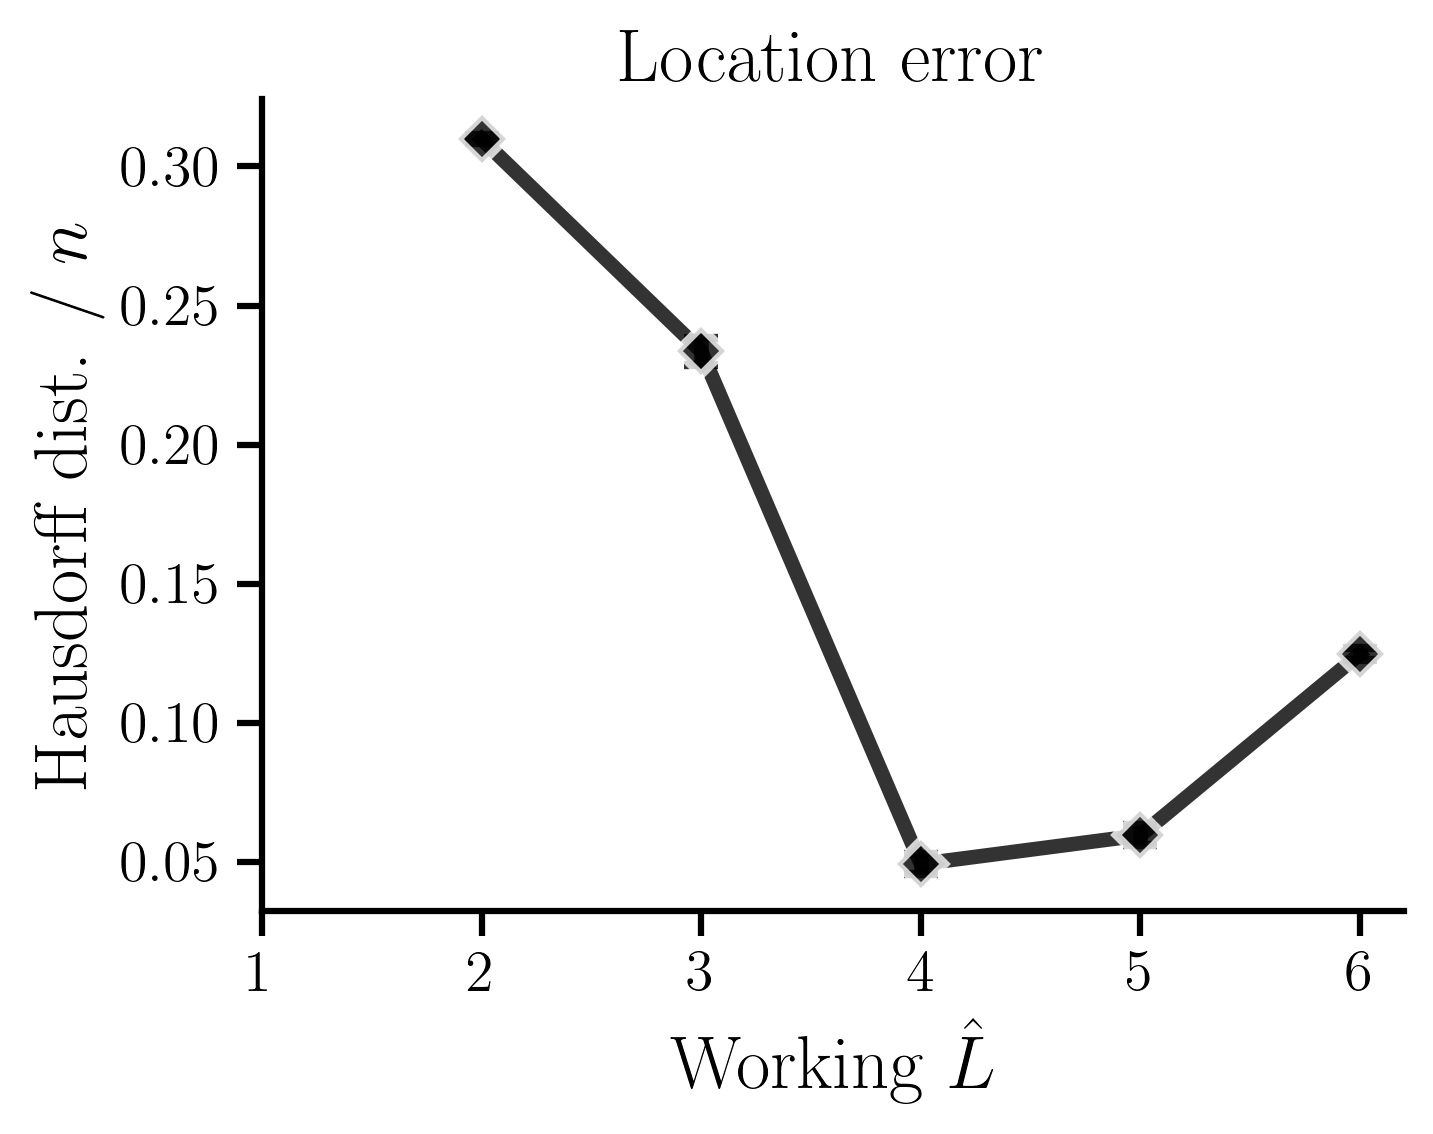

fixed_L_location_box


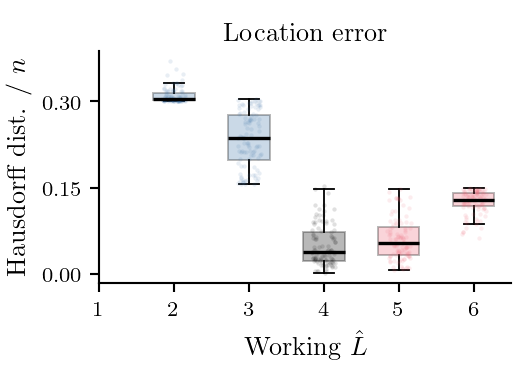

/tmp/ipykernel_3246750/3717053239.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


fixed_L_histograms: maximum density 48.57; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


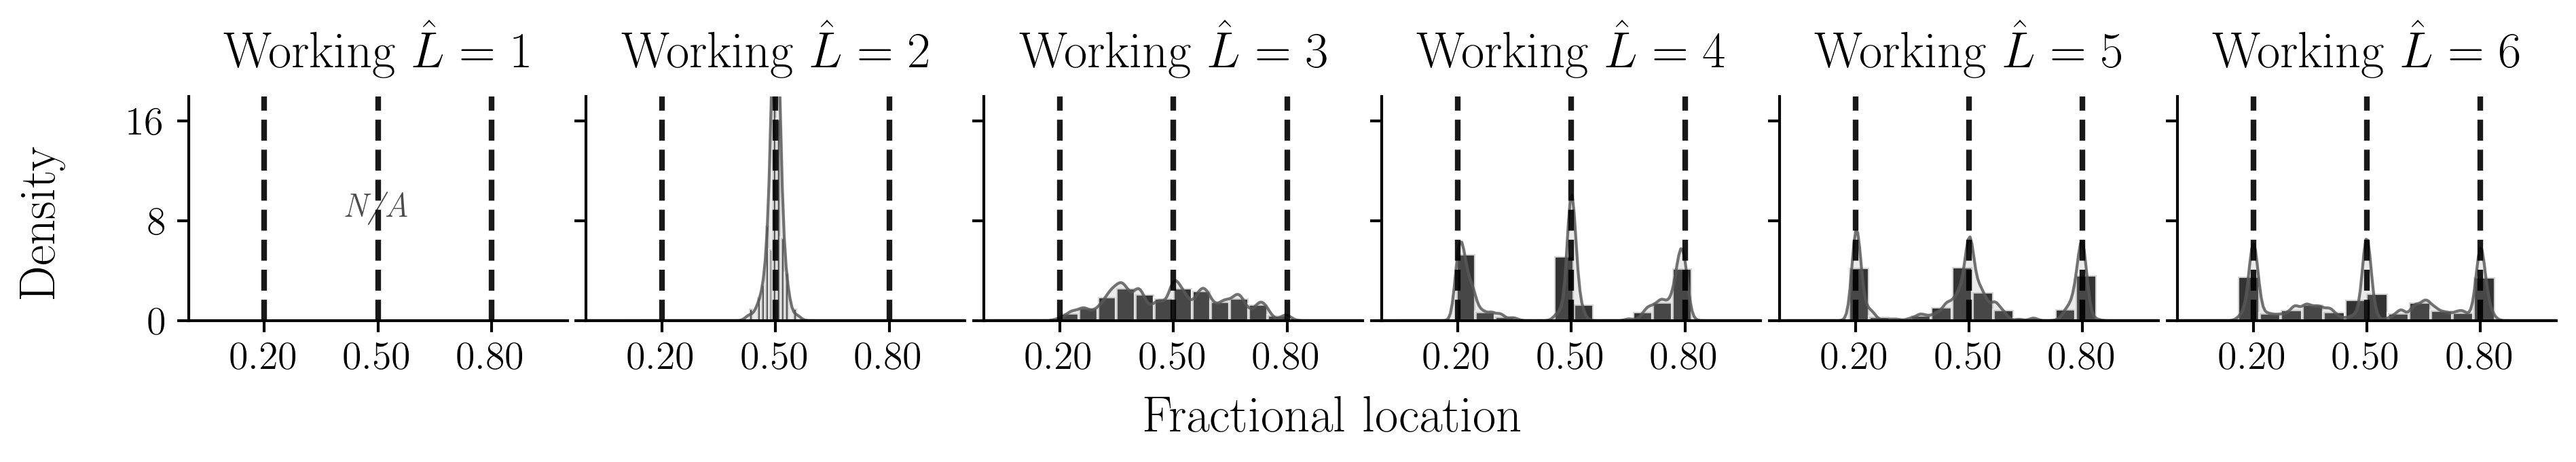

In [2]:
saved=load_saved('results/E_L_fixedL_L1to6_100paired_seed20260916.pkl')
trials,params=saved['trials'],saved['params']
Ls=np.asarray(params['working_L']);n=params['N'];truth=np.asarray(params['true_cp'])/n
groups=[[r[int(L)]['conditional_haus'] for r in trials] for L in Ls]
print('Working L-hat | finite trials | mean | median')
for L,v in zip(Ls,groups):
    v=clean(v);print(L,len(v),np.mean(v) if len(v) else 'undefined',np.median(v) if len(v) else 'undefined')
with plt.rc_context(PAPER_STYLE):
    simple_summary(groups,Ls,r'Working $\hat{L}$',r'Hausdorff dist. / $n$',
        'fixed_L_location_line',kind='line',error='se',title='Location error')
    simple_summary(groups,Ls,r'Working $\hat{L}$',r'Hausdorff dist. / $n$',
        'fixed_L_location_box',colors=['#4477AA' if L<4 else 'black' if L==4 else '#EE6677' for L in Ls],
        title='Location error')
    pools=[np.concatenate([np.asarray(r[int(L)]['cp'])/n for r in trials]) for L in Ls]
    histogram_grid([pools],['']*len(Ls),['black']*len(Ls),truth,'fixed_L_histograms',
        panel_titles=[[rf'Working $\hat{{L}}={L}$' for L in Ls]])

In [3]:
verify_sources()

Exported 3 figures to results/consistent_plots_20261102/E_L_fixed; saved inputs unchanged.
